# COMP4318/5318 Assignment 2: Image Classification

### Group number: ...  , SID1: ... , SID2: ..., SID3: ..., SID4: ... 

This template notebook includes code to load the  dataset and a skeleton for the main sections that should be included in the notebook. Please stick to this struture for your submitted notebook.

Please focus on making your code clear, with appropriate variable names and whitespace. Include comments and markdown text to aid the readability of your code where relevant. See the specification and marking criteria in the associated specification to guide you when completing your implementation.

## Setup and dependencies
Please use this section to list and set up all your required libraries/dependencies and your plotting environment.

This notebook was run locally (CPU only) with Python 3.11 and:

| Library | Version | Use |
| --- | --- | --- |
| keras | 3.15.1 | CNN definition and training (TensorFlow backend) |
| tensorflow | 2.21.0 | Keras backend |
| scikit-learn | 1.9.1 | Train/validation split, parameter grid, metrics |
| numpy | 2.4.6 | Array handling |
| pandas | 3.1.0 | Result tables and CSV export |
| matplotlib | 3.11.2 | Plots |

In [1]:
# File paths and runtime measurement
import os
from pathlib import Path
from time import perf_counter

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # hide TensorFlow start-up messages

# Data handling and visualisation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Neural network (Keras 3 with the TensorFlow backend)
import keras
from keras import layers

# Data split, hyperparameter search, and evaluation
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

print("Keras:", keras.__version__, "| backend:", keras.backend.backend())

# Random seed for reproducibility (same seed as the other members)
SEED_CNN = 42
keras.utils.set_random_seed(SEED_CNN)

# CSV files shared with the rest of the group are written here
RESULTS_DIR_CNN = Path("results_cnn")
RESULTS_DIR_CNN.mkdir(exist_ok=True)

Keras: 3.15.1 | backend: tensorflow


## 1. Data loading, exploration, and preprocessing


Code to load the dataset is provided in the following cell. Please proceed with your data exploration and preprocessing in the remainder of this section.

In [2]:
# Load the dataset training and test sets as numpy arrays.
# The template expects the Assignment2Data folder next to the notebook;
# the second location matches the unzipped Canvas download.
DATA_CANDIDATES_CNN = [
    Path("Assignment2Data"),
    Path("Assignment2Data-1") / "Assignment2Data",
]
DATA_DIR_CNN = next(
    path for path in DATA_CANDIDATES_CNN if (path / "X_train.npy").exists()
)

X_train_all_cnn = np.load(DATA_DIR_CNN / "X_train.npy", allow_pickle=False)
y_train_all_cnn = np.load(
    DATA_DIR_CNN / "y_train.npy", allow_pickle=False
).astype("int64").ravel()
X_test_img_cnn = np.load(DATA_DIR_CNN / "X_test.npy", allow_pickle=False)
y_test_cnn = np.load(
    DATA_DIR_CNN / "y_test.npy", allow_pickle=False
).astype("int64").ravel()

# PathMNIST class names (MedMNIST v2)
CLASS_NAMES_CNN = [
    "adipose",
    "background",
    "debris",
    "lymphocytes",
    "mucus",
    "smooth muscle",
    "normal colon mucosa",
    "cancer-assoc. stroma",
    "colorectal adenocarcinoma epith.",
]
NUM_CLASSES_CNN = len(CLASS_NAMES_CNN)
INPUT_SHAPE_CNN = X_train_all_cnn.shape[1:]

print("Training images:", X_train_all_cnn.shape, X_train_all_cnn.dtype)
print("Test images:", X_test_img_cnn.shape, X_test_img_cnn.dtype)
print("Number of classes:", NUM_CLASSES_CNN)

Training images: (32000, 28, 28, 3) uint8
Test images: (8000, 28, 28, 3) uint8
Number of classes: 9


#### Training/validation split for the CNN

The CNN uses the **original 28×28×3 images**, not Member A's 357 extracted features: the features summarise colour per block and lose the pixel layout that convolutions rely on.

To keep the comparison fair, the CNN is tuned on **the same stratified 80/20 split as the other two models** (25,600 training and 6,400 validation images). The split is recreated with the same call and seed Member A used, so this notebook does not depend on any extra files. If the shared `split_indices.npz` file is present, the cell checks that the indices match.

In [3]:
# Recreate Member A's stratified split (same function, test size, and seed).
fit_idx_cnn, val_idx_cnn = train_test_split(
    np.arange(len(y_train_all_cnn)),
    test_size=0.2,
    stratify=y_train_all_cnn,
    random_state=SEED_CNN,
)

# Optional check against the shared split file, if it is available.
for split_path in [Path("split_indices.npz"), Path("data") / "split_indices.npz"]:
    if split_path.exists():
        with np.load(split_path, allow_pickle=False) as shared_split:
            assert np.array_equal(fit_idx_cnn, shared_split["fit_idx"])
            assert np.array_equal(val_idx_cnn, shared_split["val_idx"])
        print("Split matches", split_path)
        break

print("Training subset:", len(fit_idx_cnn))
print("Validation subset:", len(val_idx_cnn))

Training subset: 25600
Validation subset: 6400


#### CNN preprocessing

The CNN uses two preprocessing steps. The (28, 28, 3) layout is kept throughout, because convolutional filters need neighbouring pixels to stay next to each other.

1. **Scaling:** convert the `uint8` pixels to `float32` and divide by 255, so every value lies in [0, 1].
2. **Per-channel standardisation:** subtract each colour channel's mean and divide by its standard deviation. The statistics are computed on the training subset only and then applied unchanged to the validation images. For the final model they are recomputed on all training images and applied to the test images, the same pattern Member B uses for the MLP's scaler.

**Why standardise?** The scaled images are far from zero-centred (channel means of about 0.74, 0.53 and 0.71, because H&E slides are mostly pink/white). Non-centred inputs make gradient descent poorly conditioned [LeCun et al., *Efficient BackProp*, 1998].

We first ran the full search below *without* standardisation (results kept in `results_cnn/initial_search_unstandardised/`). The CNN underfitted: the best configuration reached only 0.82 validation macro F1, with training accuracy still below 0.88 after 23–30 epochs. Validation accuracy tracked training accuracy closely, so the problem was slow learning, not overfitting. In a 6-epoch check with otherwise identical settings, standardising raised validation accuracy at epoch 5 from about 0.70 to 0.84.

**Considered but not used:**
- **Resizing or cropping.** The images are already small tissue patches with no single centred object.
- **Data augmentation (flips/rotations).** It would multiply the CPU training time, and the aim is to compare the three algorithms under similar conditions. It is listed as future work.

In [5]:
def fit_channel_stats_cnn(images):
    """Per-channel mean and standard deviation of images scaled to [0, 1]."""
    # float64 accumulation: summing ~20 million float32 values loses precision.
    scaled = images.astype("float64") / 255.0
    return (
        scaled.mean(axis=(0, 1, 2)).astype("float32"),
        scaled.std(axis=(0, 1, 2)).astype("float32"),
    )


def preprocess_cnn(images, channel_mean, channel_std):
    """Scale uint8 RGB pixels to [0, 1], then standardise each colour channel."""
    scaled = images.astype("float32") / 255.0
    return ((scaled - channel_mean) / channel_std).astype("float32")


# Channel statistics come from the training subset only.
channel_mean_cnn, channel_std_cnn = fit_channel_stats_cnn(X_train_all_cnn[fit_idx_cnn])

X_fit_cnn = preprocess_cnn(X_train_all_cnn[fit_idx_cnn], channel_mean_cnn, channel_std_cnn)
y_fit_cnn = y_train_all_cnn[fit_idx_cnn]

X_val_cnn = preprocess_cnn(X_train_all_cnn[val_idx_cnn], channel_mean_cnn, channel_std_cnn)
y_val_cnn = y_train_all_cnn[val_idx_cnn]

print("Channel mean (R, G, B):", np.round(channel_mean_cnn, 3))
print("Channel std  (R, G, B):", np.round(channel_std_cnn, 3))
print("Training subset:", X_fit_cnn.shape, X_fit_cnn.dtype)
print("Validation subset:", X_val_cnn.shape, X_val_cnn.dtype)

Channel mean (R, G, B): [0.74  0.533 0.706]
Channel std  (R, G, B): [0.125 0.179 0.126]
Training subset: (25600, 28, 28, 3) float32
Validation subset: (6400, 28, 28, 3) float32


### Examples of preprocessed data
Please print/display some examples of your preprocessed data here.

Mean after preprocessing (R, G, B): [-0.  0. -0.]
Std after preprocessing  (R, G, B): [1. 1. 1.]
Value range: [-5.91, 2.55]


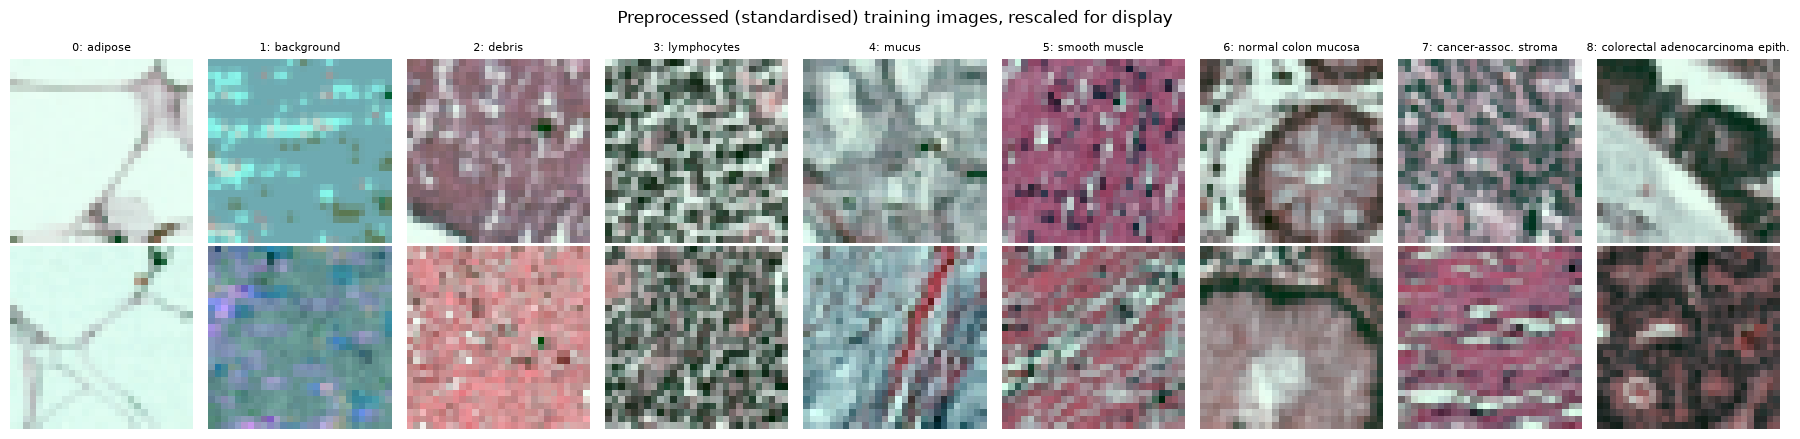

In [6]:
# Per-channel statistics of the preprocessed training subset (should be about 0 and 1)
print("Mean after preprocessing (R, G, B):",
      np.round(X_fit_cnn.mean(axis=(0, 1, 2), dtype="float64"), 3))
print("Std after preprocessing  (R, G, B):",
      np.round(X_fit_cnn.std(axis=(0, 1, 2), dtype="float64"), 3))
print(f"Value range: [{X_fit_cnn.min():.2f}, {X_fit_cnn.max():.2f}]")

# Two preprocessed training images from each class. Standardised values are not in [0, 1],
# so each image is min-max rescaled for display only.
fig, axes = plt.subplots(2, NUM_CLASSES_CNN, figsize=(18, 4.5))
for class_id, class_name in enumerate(CLASS_NAMES_CNN):
    class_rows = np.flatnonzero(y_fit_cnn == class_id)[:2]
    for row, sample in enumerate(class_rows):
        image = X_fit_cnn[sample]
        axes[row, class_id].imshow((image - image.min()) / (image.max() - image.min()))
        axes[row, class_id].axis("off")
    axes[0, class_id].set_title(f"{class_id}: {class_name}", fontsize=8)

fig.suptitle("Preprocessed (standardised) training images, rescaled for display")
plt.tight_layout()
plt.show()

## 2. Algorithm design and setup

### Algorithm of choice from first six weeks of course

### Fully connected neural network

### Convolutional neural network

The CNN takes the standardised 28×28×3 images directly. It has three convolutional blocks followed by a small fully connected classifier:

| Layer | Details |
| --- | --- |
| Block 1 | Conv2D (`base_filters` filters, 3×3, same padding, ReLU) → MaxPool 2×2 → Dropout (28×28 → 14×14) |
| Block 2 | Conv2D (2 × `base_filters`, 3×3, same padding, ReLU) → MaxPool 2×2 → Dropout (14×14 → 7×7) |
| Block 3 | Conv2D (4 × `base_filters`, 3×3, same padding, ReLU) → MaxPool 2×2 → Dropout (7×7 → 3×3) |
| Classifier | Flatten (3×3×channels) → Dense 128 + ReLU → Dropout → Dense 9 + softmax |

**Why this design:**
- Three blocks reduce the image from 28×28 to 3×3. The last convolution then sees most of the tissue patch, and stacking three layers builds a hierarchy from colour/edges to textures to tissue structure.
- The number of filters doubles in each block as the feature map shrinks, which is the usual way to trade spatial resolution for more feature channels.
- 3×3 kernels with "same" padding keep the borders of these small images.
- Max pooling halves the resolution and makes the features tolerant to small shifts. Dropout is the regularisation option tested in the search.
- The model uses the Adam optimiser and sparse categorical cross-entropy, because the labels are integer class IDs (the same choice as the MLP).

**Rough experiments that shaped the design** (short trial runs on the shared split, 32 base filters, learning rate 0.001):

| Variant | Params | s/epoch | Val acc after 6 epochs |
| --- | --- | --- | --- |
| 2 blocks, 1 conv each, *unstandardised* inputs | 422k | 8.6 | 0.733 |
| 2 blocks, 1 conv each | 422k | 8.5 | 0.814 (0.837 at epoch 5) |
| **3 blocks, 1 conv each (chosen)** | **242k** | **9.8** | **0.870** |
| 2 blocks, 2 convs each | 468k | 16.2 | 0.861 |
| 2 blocks + batch normalisation | 422k | 23.4 | 0.855 |

All variants except the first use standardised inputs.

- **The third block was chosen** because it reached the highest validation accuracy, in about 60% of the time per epoch of two convolutions per block. It also has fewer parameters: the flattened map is 3×3 instead of 7×7, so the dense layer is much smaller.
- **Batch normalisation was not used.** With unstandardised inputs, its inference-mode accuracy collapsed (about 0.61 even on the training images, while the same network scored about 0.80 on validation using per-batch statistics). With standardised inputs it worked (0.855), but it was nearly three times slower per epoch on this CPU and still below the three-block network. That would have limited how many configurations could be searched, so each block uses one convolution.

In [7]:
def build_cnn(
    input_shape,
    num_classes,
    base_filters=32,
    dropout_rate=0.3,
    learning_rate=0.001,
    kernel_size=3,
    dense_units=128,
):
    """Build and compile a configurable three-block CNN classifier."""
    model = keras.Sequential(name="cnn")
    model.add(keras.Input(shape=input_shape))

    # Convolutional blocks; each block doubles the filters of the previous one.
    for block, filters in enumerate(
        (base_filters, base_filters * 2, base_filters * 4), start=1
    ):
        model.add(layers.Conv2D(
            filters, kernel_size, padding="same", activation="relu",
            name=f"conv{block}",
        ))
        model.add(layers.MaxPooling2D(pool_size=2, name=f"maxpool{block}"))
        model.add(layers.Dropout(dropout_rate, name=f"dropout{block}"))

    # Fully connected classifier
    model.add(layers.Flatten(name="flatten"))
    model.add(layers.Dense(dense_units, activation="relu", name="dense"))
    model.add(layers.Dropout(dropout_rate, name="dropout_dense"))
    model.add(layers.Dense(num_classes, activation="softmax", name="output"))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    return model


# Create an initial model and display its architecture.
keras.utils.set_random_seed(SEED_CNN)

initial_cnn = build_cnn(
    input_shape=INPUT_SHAPE_CNN,
    num_classes=NUM_CLASSES_CNN,
)

initial_cnn.summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 28, 28, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool1 (MaxPooling2D)         │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool2 (MaxPooling2D)         │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout2 (Dropout)              │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool3 (MaxPooling2D)         │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout3 (Dropout)              │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_dense (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241,993 (945.29 KB)

 Trainable params: 241,993 (945.29 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Hyperparameter tuning

### Algorithm of choice from first six weeks of course

### Fully connected neural network

### Convolutional neural network

In [8]:
# Compare three hyperparameters across eight configurations.
param_grid_cnn = {
    "base_filters": [16, 32],
    "dropout_rate": [0.0, 0.3],
    "learning_rate": [0.001, 0.0003],
}

MAX_EPOCHS_CNN = 30
BATCH_SIZE_CNN = 128
PATIENCE_CNN = 5

configs_cnn = list(ParameterGrid(param_grid_cnn))
print("Number of configurations:", len(configs_cnn))

Number of configurations: 8


We evaluate eight configurations by varying three hyperparameters:

- **Number of filters** (`base_filters` 16 or 32; blocks 2 and 3 use 2× and 4× as many). This controls how many local patterns each layer can detect, and so the capacity and the runtime of the network.
- **Dropout rate** (0.0 or 0.3). This controls regularisation: dropout randomly switches off units during training, which reduces overfitting.
- **Learning rate** (0.001 or 0.0003). This is the Adam step size: larger steps converge faster, while smaller steps are more stable but need more epochs.

Dropout and learning rate use the same kind of values as the MLP search, so the effect of each hyperparameter can be compared across the two networks. The number of filters is the CNN's counterpart to the MLP's hidden-layer width.

We use a grid search on the shared validation split rather than cross-validation. Each CNN fit takes minutes on a CPU, so 5-fold cross-validation would multiply the runtime by five. The fixed validation split is also exactly the one used to tune the other two models.

All configurations use the same split, random seed, batch size of 128 and a maximum of 30 epochs. Early stopping monitors validation loss with a patience of five epochs and restores the weights with the lowest validation loss. Configurations are ranked by validation macro F1, with accuracy as the secondary criterion (the same rule as the MLP), so each class counts equally despite the class imbalance. Runtime and epoch counts are recorded for every configuration.

**Note:** this search takes about half an hour on a CPU. Its outputs are kept, and Section 4 does not depend on these cells.

In [ ]:
results_cnn = []
histories_cnn = {}

for trial_id, config in enumerate(configs_cnn, start=1):
    # Start each configuration with a fresh model.
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED_CNN)

    print(f"\nConfiguration {trial_id}/{len(configs_cnn)}: {config}", flush=True)

    model_cnn = build_cnn(
        input_shape=INPUT_SHAPE_CNN,
        num_classes=NUM_CLASSES_CNN,
        **config,
    )

    early_stopping_cnn = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=PATIENCE_CNN,
        restore_best_weights=True,
    )

    start_time = perf_counter()

    history_cnn = model_cnn.fit(
        X_fit_cnn,
        y_fit_cnn,
        validation_data=(X_val_cnn, y_val_cnn),
        epochs=MAX_EPOCHS_CNN,
        batch_size=BATCH_SIZE_CNN,
        callbacks=[early_stopping_cnn],
        shuffle=True,
        verbose=0,
    )

    fit_seconds = perf_counter() - start_time

    # Evaluate the restored (best-epoch) model on the validation set.
    val_probabilities = model_cnn.predict(X_val_cnn, batch_size=512, verbose=0)
    val_predictions = np.argmax(val_probabilities, axis=1)

    val_accuracy = accuracy_score(y_val_cnn, val_predictions)
    val_macro_f1 = f1_score(
        y_val_cnn, val_predictions, average="macro", zero_division=0,
    )

    best_epoch = int(np.argmin(history_cnn.history["val_loss"]) + 1)
    epochs_run = len(history_cnn.history["loss"])

    results_cnn.append({
        "trial": trial_id,
        **config,
        "n_params": model_cnn.count_params(),
        "best_epoch": best_epoch,
        "epochs_run": epochs_run,
        "train_accuracy_at_best": history_cnn.history["accuracy"][best_epoch - 1],
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1,
        "fit_seconds": fit_seconds,
        "seconds_per_epoch": fit_seconds / epochs_run,
    })

    # Keep learning curves for later plots.
    histories_cnn[trial_id] = history_cnn.history

    print(
        f"Validation accuracy: {val_accuracy:.4f} | "
        f"Macro F1: {val_macro_f1:.4f} | "
        f"Best epoch: {best_epoch}/{epochs_run} | "
        f"Time: {fit_seconds:.1f}s",
        flush=True,
    )

# Rank configurations by macro F1, then accuracy.
results_df_cnn = pd.DataFrame(results_cnn).sort_values(
    by=["val_macro_f1", "val_accuracy"],
    ascending=[False, False],
).reset_index(drop=True)

results_df_cnn.round(4)



Configuration 1/8: {'base_filters': 16, 'dropout_rate': 0.0, 'learning_rate': 0.001}
Validation accuracy: 0.8677 | Macro F1: 0.8653 | Best epoch: 11/16 | Time: 126.9s

Configuration 2/8: {'base_filters': 16, 'dropout_rate': 0.0, 'learning_rate': 0.0003}
Validation accuracy: 0.8522 | Macro F1: 0.8480 | Best epoch: 29/30 | Time: 221.6s

Configuration 3/8: {'base_filters': 16, 'dropout_rate': 0.3, 'learning_rate': 0.001}


In [ ]:
# Save the search results and learning curves for the group's tables and plots.
results_df_cnn.to_csv(RESULTS_DIR_CNN / "cnn_tuning_results.csv", index=False)

history_rows_cnn = [
    {"trial": trial_id, "epoch": epoch + 1,
     **{metric: values[epoch] for metric, values in history.items()}}
    for trial_id, history in histories_cnn.items()
    for epoch in range(len(history["loss"]))
]
pd.DataFrame(history_rows_cnn).to_csv(
    RESULTS_DIR_CNN / "cnn_tuning_histories.csv", index=False
)

print("Saved:", sorted(path.name for path in RESULTS_DIR_CNN.glob("cnn_tuning_*.csv")))

Saved: ['cnn_tuning_histories.csv', 'cnn_tuning_results.csv']


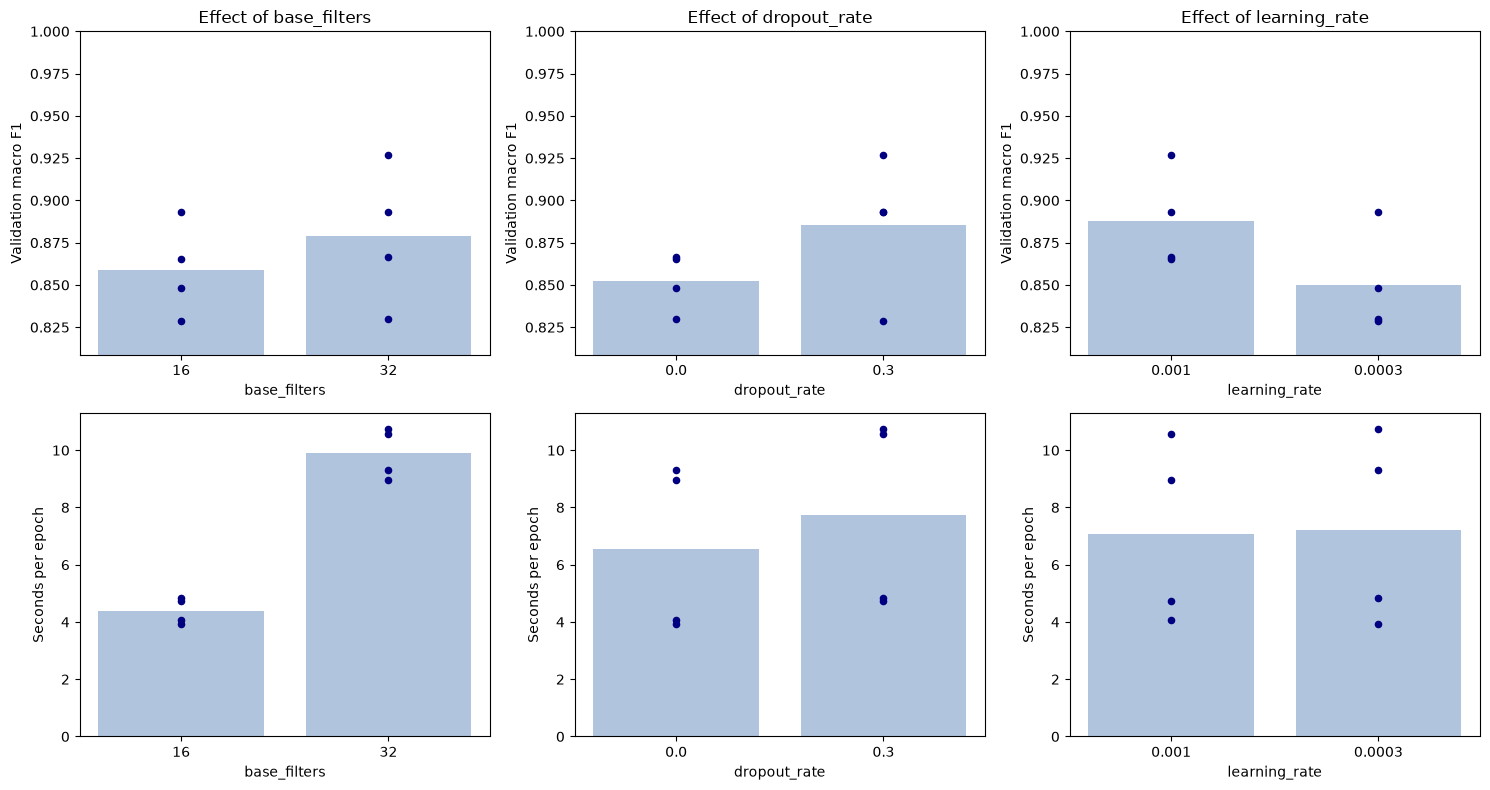

In [10]:
# Effect of each hyperparameter: mean over the four configurations sharing a value,
# with the individual configurations shown as points.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for col, name in enumerate(param_grid_cnn):
    values = param_grid_cnn[name]
    labels = [str(value) for value in values]

    for row, (metric, ylabel) in enumerate([
        ("val_macro_f1", "Validation macro F1"),
        ("seconds_per_epoch", "Seconds per epoch"),
    ]):
        ax = axes[row, col]
        groups = [results_df_cnn.loc[results_df_cnn[name] == value, metric] for value in values]
        ax.bar(labels, [group.mean() for group in groups], color="lightsteelblue", label="Mean")
        for position, group in enumerate(groups):
            ax.scatter([position] * len(group), group, color="navy", zorder=3, s=20)
        ax.set_xlabel(name)
        ax.set_ylabel(ylabel)

    low = results_df_cnn["val_macro_f1"].min()
    axes[0, col].set_ylim(low - 0.02, 1.0)
    axes[0, col].set_title(f"Effect of {name}")

plt.tight_layout()
plt.show()

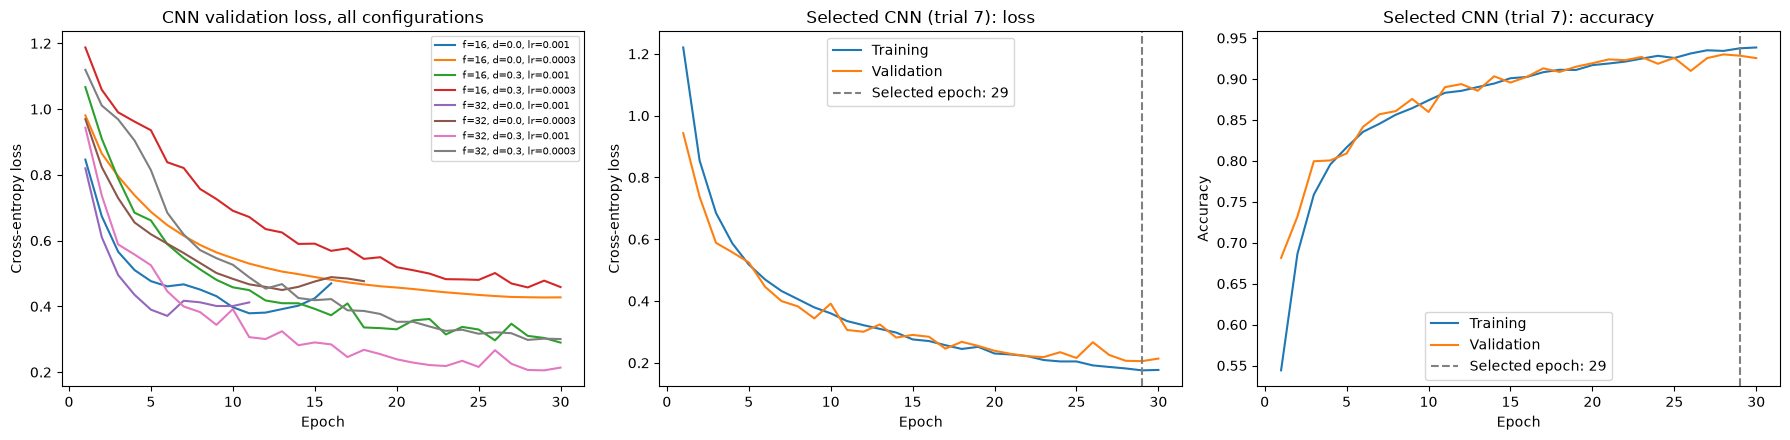

In [11]:
# Validation loss of every configuration, and the learning curves of the selected one.
best_trial_cnn = int(results_df_cnn.iloc[0]["trial"])
best_epoch_cnn = int(results_df_cnn.iloc[0]["best_epoch"])
best_history_cnn = histories_cnn[best_trial_cnn]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

for _, row in results_df_cnn.sort_values("trial").iterrows():
    history = histories_cnn[int(row["trial"])]
    axes[0].plot(
        range(1, len(history["val_loss"]) + 1), history["val_loss"],
        label=(f"f={int(row['base_filters'])}, d={row['dropout_rate']}, "
               f"lr={row['learning_rate']}"),
    )
axes[0].set_title("CNN validation loss, all configurations")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend(fontsize=7)

epochs_cnn = range(1, len(best_history_cnn["loss"]) + 1)
for ax, metric, ylabel in [
    (axes[1], "loss", "Cross-entropy loss"),
    (axes[2], "accuracy", "Accuracy"),
]:
    ax.plot(epochs_cnn, best_history_cnn[metric], label="Training")
    ax.plot(epochs_cnn, best_history_cnn[f"val_{metric}"], label="Validation")
    ax.axvline(best_epoch_cnn, color="grey", linestyle="--",
               label=f"Selected epoch: {best_epoch_cnn}")
    ax.set_title(f"Selected CNN (trial {best_trial_cnn}): {metric}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend()

plt.tight_layout()
plt.show()

The selected configuration uses **32 base filters, Dropout 0.3 and learning rate 0.001** (trial 7). It reaches validation macro F1 of 0.9268 and accuracy of 0.9284, clearly ahead of the next-best configurations (0.8934 and 0.8931).

- **Learning rate:** 0.001 beats 0.0003 in all four matched comparisons. Within the 30-epoch budget the smaller step size had not converged: three of the four 0.0003 runs were still improving at epochs 28–29. This is the opposite of the MLP result, where 0.0003 was better. Each CNN epoch is far more expensive, so under a fixed epoch budget the faster rate is more useful.
- **Dropout** improves validation macro F1 in three of the four matched comparisons. Without dropout the network starts to overfit: in three of the four runs, the validation loss reaches its minimum early (epochs 6–13) and then rises, so early stopping ends training after 11–18 epochs. With dropout, the validation loss keeps decreasing until the 30-epoch limit. The exception is 16 filters with learning rate 0.0003, where slow learning combined with dropout had not converged.
- **More filters help only when combined with dropout** (+0.033 and +0.064 macro F1). Without dropout, 16 and 32 filters perform about the same (+0.002 and −0.018), because the extra capacity mainly increases overfitting. 32 filters take about 2.3× as long per epoch (≈9.9 s vs ≈4.4 s) and have about 2.5× the parameters.

The predictions held for dropout and partly for the number of filters. The prediction that the lower learning rate might reach a better minimum did not hold within this epoch budget.

The selected configuration's training and validation losses decrease together with almost no gap, and the lowest validation loss is at epoch 29 of 30. The model is therefore well regularised, but it may still be slightly under-trained; the 30-epoch limit, which kept the search to about 23 minutes, is a limitation. The final model is trained for 29 epochs.

## 4. Final models
In this section, please ensure to include cells to train each model with its best hyperparmater combination independently of the hyperparameter tuning cells, i.e. don't rely on the hyperparameter tuning cells having been run.

### Algorithm of choice from first six weeks of course

### Fully connected neural network

### Convolutional neural network

The final CNN is trained from scratch on **all 32,000 training images** with the configuration selected in Section 3. It runs for the fixed number of epochs at which that configuration reached its lowest validation loss. The settings are written out explicitly below, so this section runs even if the tuning cells are skipped. The test set is used only here, once, for the final evaluation.

In [12]:
# Configuration selected using validation macro F1 (Section 3).
FINAL_CONFIG_CNN = {
    "base_filters": 32,
    "dropout_rate": 0.3,
    "learning_rate": 0.001,
}
FINAL_EPOCHS_CNN = 29
FINAL_BATCH_SIZE_CNN = 128

In [13]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED_CNN)

start_time_cnn = perf_counter()

# Refit the channel statistics on the complete training set and preprocess it.
final_channel_mean_cnn, final_channel_std_cnn = fit_channel_stats_cnn(X_train_all_cnn)
X_train_final_cnn = preprocess_cnn(
    X_train_all_cnn, final_channel_mean_cnn, final_channel_std_cnn
)

# Train a fresh model using all training samples.
final_model_cnn = build_cnn(
    input_shape=INPUT_SHAPE_CNN,
    num_classes=NUM_CLASSES_CNN,
    **FINAL_CONFIG_CNN,
)

final_history_cnn = final_model_cnn.fit(
    X_train_final_cnn,
    y_train_all_cnn,
    epochs=FINAL_EPOCHS_CNN,
    batch_size=FINAL_BATCH_SIZE_CNN,
    shuffle=True,
    verbose=0,
)

final_fit_seconds_cnn = perf_counter() - start_time_cnn

print("Final configuration:", FINAL_CONFIG_CNN)
print("Trainable parameters:", final_model_cnn.count_params())
print("Training samples:", len(y_train_all_cnn))
print("Training epochs:", FINAL_EPOCHS_CNN)
print(f"Preprocessing and training time: {final_fit_seconds_cnn:.2f}s "
      f"({final_fit_seconds_cnn / FINAL_EPOCHS_CNN:.1f}s per epoch)")

Final configuration: {'base_filters': 32, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Trainable parameters: 241993
Training samples: 32000
Training epochs: 29
Preprocessing and training time: 371.37s (12.8s per epoch)


In [14]:
start_time_cnn = perf_counter()

# Apply the training-set channel statistics to the held-out test images.
X_test_cnn = preprocess_cnn(
    X_test_img_cnn, final_channel_mean_cnn, final_channel_std_cnn
)

test_probabilities_cnn = final_model_cnn.predict(X_test_cnn, batch_size=512, verbose=0)
test_predictions_cnn = np.argmax(test_probabilities_cnn, axis=1)

test_predict_seconds_cnn = perf_counter() - start_time_cnn

test_metrics_cnn = {
    "accuracy": accuracy_score(y_test_cnn, test_predictions_cnn),
    "macro_f1": f1_score(y_test_cnn, test_predictions_cnn, average="macro", zero_division=0),
    "weighted_f1": f1_score(y_test_cnn, test_predictions_cnn, average="weighted", zero_division=0),
    "macro_precision": precision_score(y_test_cnn, test_predictions_cnn, average="macro", zero_division=0),
    "macro_recall": recall_score(y_test_cnn, test_predictions_cnn, average="macro", zero_division=0),
}

for name, value in test_metrics_cnn.items():
    print(f"Test {name.replace('_', ' ')}: {value:.4f}")
print(f"Test preprocessing and prediction time: {test_predict_seconds_cnn:.2f}s")

print("\nClassification report:")
print(classification_report(
    y_test_cnn,
    test_predictions_cnn,
    target_names=[f"{i} {name}" for i, name in enumerate(CLASS_NAMES_CNN)],
    digits=4,
    zero_division=0,
))

Test accuracy: 0.9364
Test macro f1: 0.9343
Test weighted f1: 0.9358
Test macro precision: 0.9372
Test macro recall: 0.9330
Test preprocessing and prediction time: 1.29s

Classification report:
                                    precision    recall  f1-score   support

                         0 adipose     0.9719    0.9920    0.9819       873
                      1 background     0.9895    0.9872    0.9883       858
                          2 debris     0.8547    0.9122    0.8825       877
                     3 lymphocytes     0.9529    0.9967    0.9743       914
                           4 mucus     0.9525    0.9254    0.9387       737
                   5 smooth muscle     0.9214    0.9515    0.9362      1072
             6 normal colon mucosa     0.9474    0.8988    0.9225       682
            7 cancer-assoc. stroma     0.9050    0.7847    0.8406       813
8 colorectal adenocarcinoma epith.     0.9393    0.9489    0.9441      1174

                          accuracy          

In [15]:
# Export the final CNN results as CSV files for the combined comparison tables.
final_summary_cnn = pd.DataFrame([{
    "model": "CNN",
    "best_hyperparameters": "; ".join(f"{k}={v}" for k, v in FINAL_CONFIG_CNN.items()),
    "epochs": FINAL_EPOCHS_CNN,
    "batch_size": FINAL_BATCH_SIZE_CNN,
    "n_params": final_model_cnn.count_params(),
    "train_samples": len(y_train_all_cnn),
    "train_seconds": final_fit_seconds_cnn,
    "seconds_per_epoch": final_fit_seconds_cnn / FINAL_EPOCHS_CNN,
    "test_predict_seconds": test_predict_seconds_cnn,
    **{f"test_{name}": value for name, value in test_metrics_cnn.items()},
}])
final_summary_cnn.to_csv(RESULTS_DIR_CNN / "cnn_final_results.csv", index=False)

report_cnn = pd.DataFrame(classification_report(
    y_test_cnn, test_predictions_cnn, output_dict=True, zero_division=0,
)).T
per_class_cnn = report_cnn.iloc[:NUM_CLASSES_CNN].copy()
per_class_cnn.insert(0, "class_name", CLASS_NAMES_CNN)
per_class_cnn.index.name = "class_id"
per_class_cnn.to_csv(RESULTS_DIR_CNN / "cnn_classification_report.csv")

confusion_cnn = confusion_matrix(y_test_cnn, test_predictions_cnn, labels=range(NUM_CLASSES_CNN))
pd.DataFrame(
    confusion_cnn,
    index=[f"true_{i}" for i in range(NUM_CLASSES_CNN)],
    columns=[f"pred_{i}" for i in range(NUM_CLASSES_CNN)],
).to_csv(RESULTS_DIR_CNN / "cnn_confusion_matrix.csv")

pd.DataFrame({
    "y_true": y_test_cnn,
    "y_pred": test_predictions_cnn,
    "confidence": test_probabilities_cnn.max(axis=1),
}).to_csv(RESULTS_DIR_CNN / "cnn_test_predictions.csv", index_label="test_index")

print("Saved:", sorted(path.name for path in RESULTS_DIR_CNN.glob("*.csv")))
final_summary_cnn.round(4).T

Saved: ['cnn_classification_report.csv', 'cnn_confusion_matrix.csv', 'cnn_final_results.csv', 'cnn_test_predictions.csv', 'cnn_tuning_histories.csv', 'cnn_tuning_results.csv']


,0
model,CNN
best_hyperparameters,base_filters=32; dropout_rate=0.3; learning_ra...
epochs,29
batch_size,128
n_params,241993
train_samples,32000
train_seconds,371.3715
seconds_per_epoch,12.8059
test_predict_seconds,1.2889
test_accuracy,0.9364


#### CNN error analysis

The cells below look at the kinds of mistakes the final CNN makes:
- confusion matrices (counts, and rows normalised to recall),
- the most frequent pairs of confused classes,
- how confident the model is when it is right compared with when it is wrong,
- examples of misclassified test images.

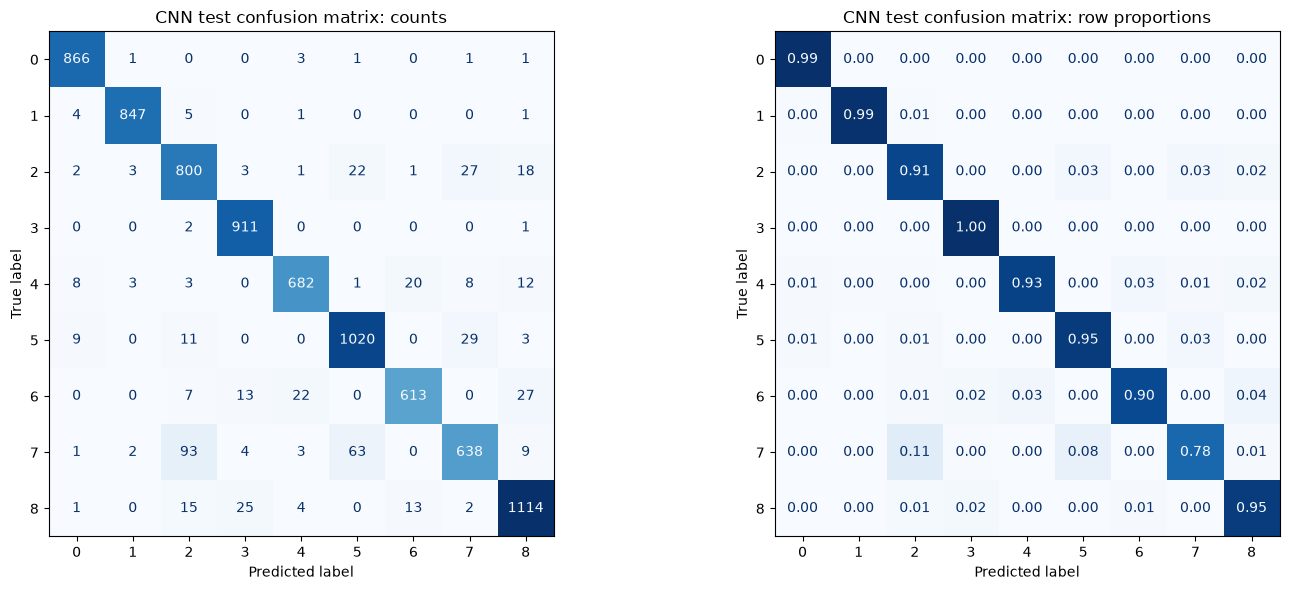

Class IDs: 0 = adipose, 1 = background, 2 = debris, 3 = lymphocytes, 4 = mucus, 5 = smooth muscle, 6 = normal colon mucosa, 7 = cancer-assoc. stroma, 8 = colorectal adenocarcinoma epith.


In [16]:
# Display counts and recall-normalised confusion matrices.
short_names_cnn = [f"{i}" for i in range(NUM_CLASSES_CNN)]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test_cnn, test_predictions_cnn,
    labels=range(NUM_CLASSES_CNN), display_labels=short_names_cnn,
    cmap="Blues", values_format="d", colorbar=False, ax=axes[0],
)
axes[0].set_title("CNN test confusion matrix: counts")

ConfusionMatrixDisplay.from_predictions(
    y_test_cnn, test_predictions_cnn,
    labels=range(NUM_CLASSES_CNN), display_labels=short_names_cnn,
    normalize="true", cmap="Blues", values_format=".2f", colorbar=False, ax=axes[1],
)
axes[1].set_title("CNN test confusion matrix: row proportions")

plt.tight_layout()
plt.show()

print("Class IDs:", ", ".join(f"{i} = {name}" for i, name in enumerate(CLASS_NAMES_CNN)))

In [17]:
# Most frequent confusions (true class -> predicted class)
off_diagonal_cnn = [
    {
        "true": f"{i} {CLASS_NAMES_CNN[i]}",
        "predicted": f"{j} {CLASS_NAMES_CNN[j]}",
        "count": int(confusion_cnn[i, j]),
        "share_of_true_class": confusion_cnn[i, j] / confusion_cnn[i].sum(),
    }
    for i in range(NUM_CLASSES_CNN)
    for j in range(NUM_CLASSES_CNN)
    if i != j and confusion_cnn[i, j] > 0
]
top_confusions_cnn = (
    pd.DataFrame(off_diagonal_cnn)
    .sort_values("count", ascending=False)
    .head(8)
    .reset_index(drop=True)
)
top_confusions_cnn.to_csv(RESULTS_DIR_CNN / "cnn_top_confusions.csv", index=False)

n_errors_cnn = int((test_predictions_cnn != y_test_cnn).sum())
print(f"Misclassified test images: {n_errors_cnn} of {len(y_test_cnn)}")
print(f"Share of all errors in the top 8 pairs: {top_confusions_cnn['count'].sum() / n_errors_cnn:.1%}")
top_confusions_cnn.round(3)

Misclassified test images: 509 of 8000
Share of all errors in the top 8 pairs: 60.5%


,true,predicted,count,share_of_true_class
0,7 cancer-assoc. stroma,2 debris,93,0.114
1,7 cancer-assoc. stroma,5 smooth muscle,63,0.077
2,5 smooth muscle,7 cancer-assoc. stroma,29,0.027
3,2 debris,7 cancer-assoc. stroma,27,0.031
4,6 normal colon mucosa,8 colorectal adenocarcinoma epith.,27,0.040
5,8 colorectal adenocarcinoma epith.,3 lymphocytes,25,0.021
6,2 debris,5 smooth muscle,22,0.025
7,6 normal colon mucosa,4 mucus,22,0.032


Mean confidence when correct:   0.961
Mean confidence when incorrect: 0.703
Errors made with confidence > 0.9: 17.5% of all errors


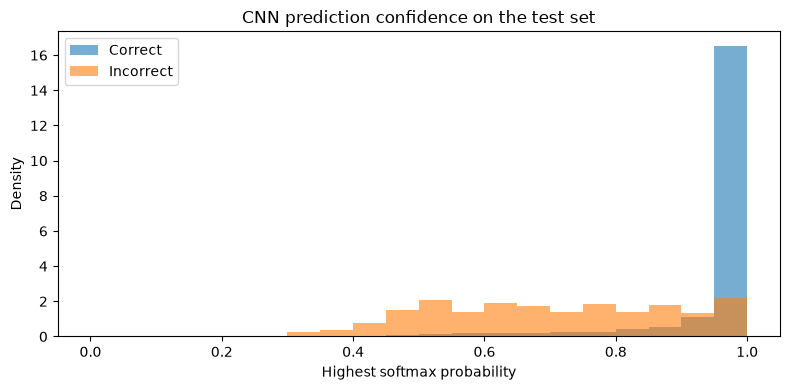

In [18]:
# Confidence (highest softmax probability) of correct and incorrect predictions
confidence_cnn = test_probabilities_cnn.max(axis=1)
correct_mask_cnn = test_predictions_cnn == y_test_cnn

print(f"Mean confidence when correct:   {confidence_cnn[correct_mask_cnn].mean():.3f}")
print(f"Mean confidence when incorrect: {confidence_cnn[~correct_mask_cnn].mean():.3f}")
print(f"Errors made with confidence > 0.9: "
      f"{(confidence_cnn[~correct_mask_cnn] > 0.9).mean():.1%} of all errors")

plt.figure(figsize=(8, 4))
bins = np.linspace(0, 1, 21)
plt.hist(confidence_cnn[correct_mask_cnn], bins=bins, alpha=0.6, density=True, label="Correct")
plt.hist(confidence_cnn[~correct_mask_cnn], bins=bins, alpha=0.6, density=True, label="Incorrect")
plt.xlabel("Highest softmax probability")
plt.ylabel("Density")
plt.title("CNN prediction confidence on the test set")
plt.legend()
plt.tight_layout()
plt.show()

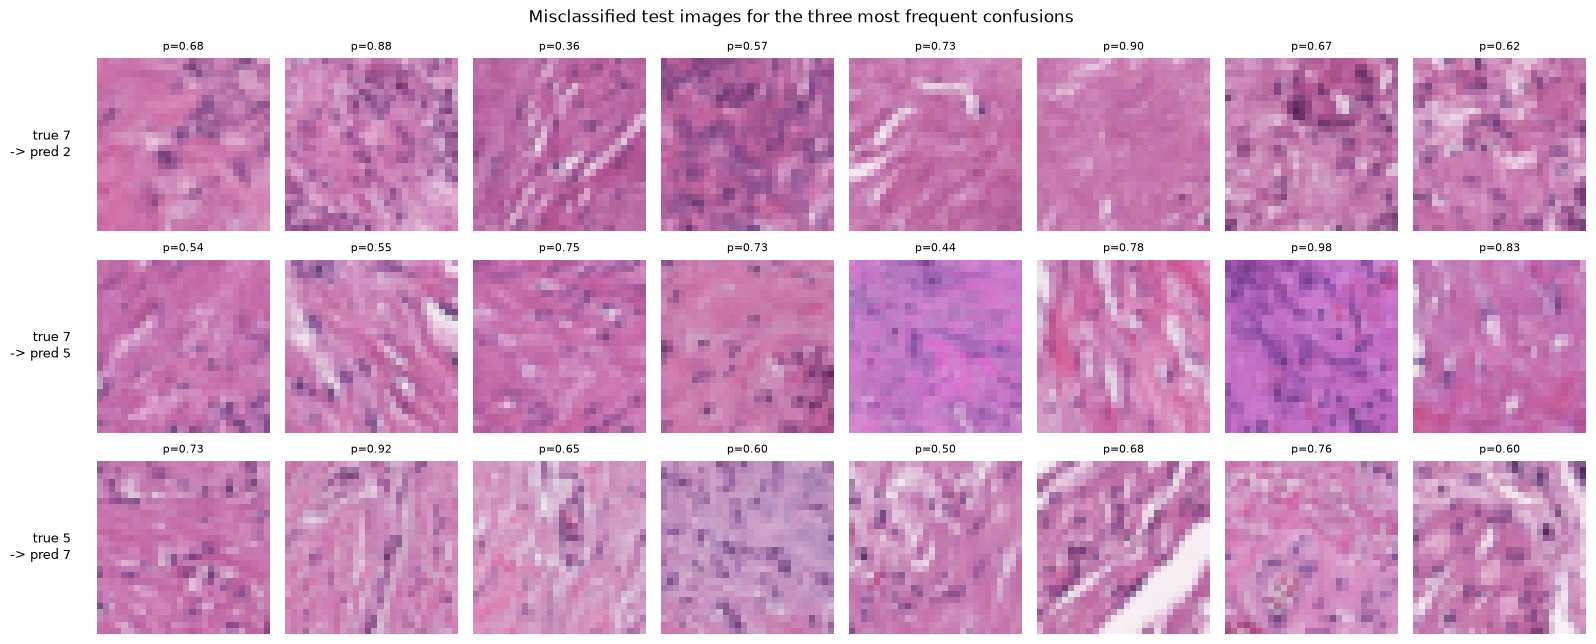

In [19]:
# Misclassified examples from the most frequent confusion pairs
rng_cnn = np.random.default_rng(SEED_CNN)
fig, axes = plt.subplots(3, 8, figsize=(16, 6.6))

for row, (_, pair) in enumerate(top_confusions_cnn.head(3).iterrows()):
    true_id = int(pair["true"].split()[0])
    pred_id = int(pair["predicted"].split()[0])
    pair_rows = np.flatnonzero((y_test_cnn == true_id) & (test_predictions_cnn == pred_id))
    chosen = rng_cnn.choice(pair_rows, size=min(8, len(pair_rows)), replace=False)

    for col in range(8):
        ax = axes[row, col]
        ax.axis("off")
        if col < len(chosen):
            ax.imshow(X_test_img_cnn[chosen[col]])
            ax.set_title(f"p={confidence_cnn[chosen[col]]:.2f}", fontsize=8)
    axes[row, 0].text(
        -0.15, 0.5,
        f"true {true_id}\n-> pred {pred_id}",
        transform=axes[row, 0].transAxes, ha="right", va="center", fontsize=9,
    )

fig.suptitle("Misclassified test images for the three most frequent confusions")
plt.tight_layout()
plt.show()

The final CNN is retrained from scratch on all 32,000 training images for 29 epochs, with channel statistics refitted on the full training set. Training takes 371 s (12.8 s per epoch, more than in the search because each epoch has 25% more images). Preprocessing and prediction for the 8,000 test images take 1.3 s.

On the test set the CNN reaches **accuracy 0.9364, macro F1 0.9343 and weighted F1 0.9358**. This is close to its validation accuracy (0.9284), so the selection did not overfit the validation split. It is higher than both the MLP (0.8772 / 0.8737) and the Random Forest (0.8606 / 0.8562). The CNN makes 509 errors, about half as many as the MLP (982). The cost is runtime: on this machine it takes about 58× longer to train than the MLP and about 14× longer to predict.

**Error analysis.**
- **Easy classes:** adipose, background and lymphocytes are almost perfect (F1 ≥ 0.97). They can be recognised by colour alone: white fat cells, empty background and dense purple nuclei.
- **Hardest class:** cancer-associated stroma (recall 0.78, F1 0.84). 93 stroma images are predicted as debris and 63 as smooth muscle, and smooth muscle and debris are in turn sometimes predicted as stroma. These three are pink, fibrous tissues that look very similar at 28×28 pixels (see the examples above).
- **Other confusions:** normal colon mucosa is sometimes predicted as adenocarcinoma epithelium (27 images); both are glandular epithelium. Adenocarcinoma is sometimes predicted as lymphocytes (25 images), where dense dark nuclei dominate. The eight most frequent confusion pairs account for 60.5% of all errors.
- **Comparison with the MLP:** F1 improves for every class. The largest gains are for normal mucosa (+0.13), debris (+0.09), stroma (+0.09) and mucus (+0.07), texture-based classes where the MLP's colour-block features carry little information. The confusion structure (stroma ↔ debris ↔ smooth muscle) is the same as the MLP's, which suggests these classes are intrinsically hard at this resolution.
- **Confidence:** the mean confidence is 0.96 for correct predictions and 0.70 for incorrect ones, so low confidence is a useful warning sign. However, 17.5% of the errors are made with confidence above 0.9. In a clinical setting, such confident mistakes would still need human review.

The test set is used only for this final evaluation and not to revise the selected configuration.

## 5. AI Acknowledgement
Include acknowledgement of AI usage here.

**Member C (CNN):** Claude (Anthropic), used through Claude Code, assisted with setting up the Python environment, writing and debugging the CNN code, running the experiments locally, diagnosing the underfitting of the first CNN version, and drafting the explanatory text from the experiment outputs. The experiments were executed locally, and all reported numbers come from those runs. Member C reviewed the code and text.